In [1]:
import requests

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 22.5726,
    "longitude": 88.3639,
    "start_date": "2025-01-01",
    "end_date": "2025-01-03",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation"
    ],
    "timezone": "Asia/Kolkata"
}

In [3]:
response = requests.get(
    url,
    params=params,
    timeout=30
)

print(response.status_code)

200


In [4]:
print(response.text)

{"latitude":22.601053,"longitude":88.31776,"generationtime_ms":0.10478496551513672,"utc_offset_seconds":19800,"timezone":"Asia/Kolkata","timezone_abbreviation":"GMT+5:30","elevation":12.0,"hourly_units":{"time":"iso8601","temperature_2m":"°C","relative_humidity_2m":"%","precipitation":"mm"},"hourly":{"time":["2025-01-01T00:00","2025-01-01T01:00","2025-01-01T02:00","2025-01-01T03:00","2025-01-01T04:00","2025-01-01T05:00","2025-01-01T06:00","2025-01-01T07:00","2025-01-01T08:00","2025-01-01T09:00","2025-01-01T10:00","2025-01-01T11:00","2025-01-01T12:00","2025-01-01T13:00","2025-01-01T14:00","2025-01-01T15:00","2025-01-01T16:00","2025-01-01T17:00","2025-01-01T18:00","2025-01-01T19:00","2025-01-01T20:00","2025-01-01T21:00","2025-01-01T22:00","2025-01-01T23:00","2025-01-02T00:00","2025-01-02T01:00","2025-01-02T02:00","2025-01-02T03:00","2025-01-02T04:00","2025-01-02T05:00","2025-01-02T06:00","2025-01-02T07:00","2025-01-02T08:00","2025-01-02T09:00","2025-01-02T10:00","2025-01-02T11:00","2025-

In [5]:
print(response.url)
print(response.headers.get("Content-Type"))

https://archive-api.open-meteo.com/v1/archive?latitude=22.5726&longitude=88.3639&start_date=2025-01-01&end_date=2025-01-03&hourly=temperature_2m&hourly=relative_humidity_2m&hourly=precipitation&timezone=Asia%2FKolkata
application/json; charset=utf-8


In [6]:
data = response.json()

print(type(data))
print(data.keys())

<class 'dict'>
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [7]:
print(data["hourly"].keys())

dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation'])


In [8]:
print(data["hourly"]["time"][:5])
print(data["hourly"]["temperature_2m"][:5])

['2025-01-01T00:00', '2025-01-01T01:00', '2025-01-01T02:00', '2025-01-01T03:00', '2025-01-01T04:00']
[16.4, 15.8, 15.3, 14.9, 14.3]


# DataProcessing

In [9]:
import pandas as pd

In [10]:
df = pd.DataFrame(data["hourly"])
df.head()

,time,temperature_2m,relative_humidity_2m,precipitation
0,2025-01-01T00:00,16.4,76,0.0
1,2025-01-01T01:00,15.8,77,0.0
2,2025-01-01T02:00,15.3,79,0.0
3,2025-01-01T03:00,14.9,82,0.0
4,2025-01-01T04:00,14.3,85,0.0


In [11]:
df.shape

(72, 4)

In [12]:
df.columns

Index(['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation'], dtype='str')

In [13]:
df.dtypes


time                        str
temperature_2m          float64
relative_humidity_2m      int64
precipitation           float64
dtype: object

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  72 non-null     str    
 1   temperature_2m        72 non-null     float64
 2   relative_humidity_2m  72 non-null     int64  
 3   precipitation         72 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 2.4 KB


In [15]:
df["time"] = pd.to_datetime(df["time"])

In [16]:
df.dtypes

time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
dtype: object

In [17]:
df["time"].dt.hour

0      0
1      1
2      2
3      3
4      4
      ..
67    19
68    20
69    21
70    22
71    23
Name: time, Length: 72, dtype: int32

In [18]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
dtype: int64

In [19]:
df["time"].duplicated().sum()

np.int64(0)

In [20]:
print("Rows:", len(df))
print("Start:", df["time"].min())
print("End:", df["time"].max())

Rows: 72
Start: 2025-01-01 00:00:00
End: 2025-01-03 23:00:00


In [21]:
df.describe()

,time,temperature_2m,relative_humidity_2m,precipitation
count,72,72.000000,72.000000,72.0
mean,2025-01-02 11:30:00,17.609722,73.194444,0.0
min,2025-01-01 00:00:00,12.000000,48.000000,0.0
25%,2025-01-01 17:45:00,14.850000,60.500000,0.0
50%,2025-01-02 11:30:00,17.100000,77.000000,0.0
75%,2025-01-03 05:15:00,20.575000,85.000000,0.0
max,2025-01-03 23:00:00,23.400000,92.000000,0.0
std,NaN,3.434668,13.792873,0.0


# Daily Analysis

In [22]:
df["date"] = df["time"].dt.date

daily_weather = df.groupby("date").agg(
    avg_temperature=("temperature_2m", "mean"),
    min_temperature=("temperature_2m", "min"),
    max_temperature=("temperature_2m", "max"),
    avg_humidity=("relative_humidity_2m", "mean"),
    total_precipitation=("precipitation", "sum")
)

daily_weather

,avg_temperature,min_temperature,max_temperature,avg_humidity,total_precipitation
date,,,,,
2025-01-01,18.383333,13.8,23.4,72.583333,0.0
2025-01-02,17.258333,12.7,22.8,73.166667,0.0
2025-01-03,17.187500,12.0,22.9,73.833333,0.0


Matplotlib is building the font cache; this may take a moment.


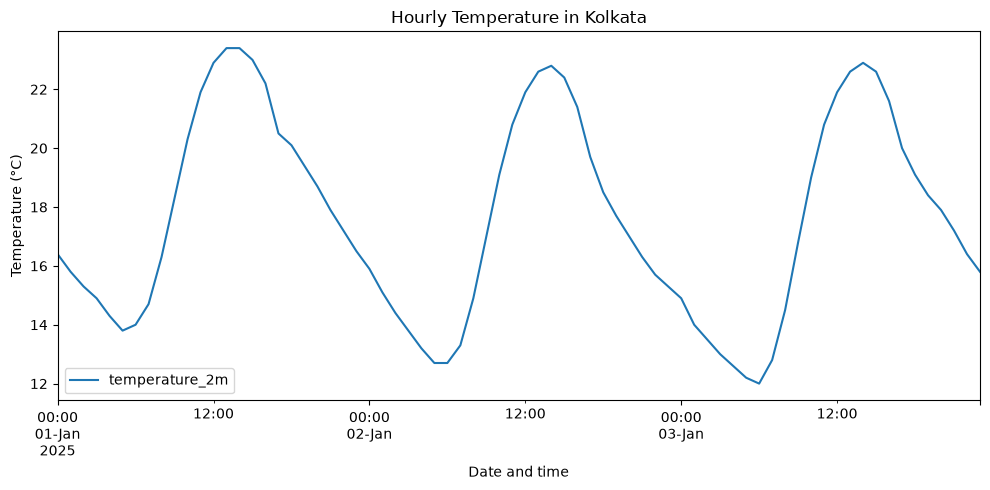

In [23]:
import matplotlib.pyplot as plt

df.plot(
    x="time",
    y="temperature_2m",
    figsize=(10, 5),
    title="Hourly Temperature in Kolkata"
)

plt.ylabel("Temperature (°C)")
plt.xlabel("Date and time")
plt.tight_layout()
plt.show()

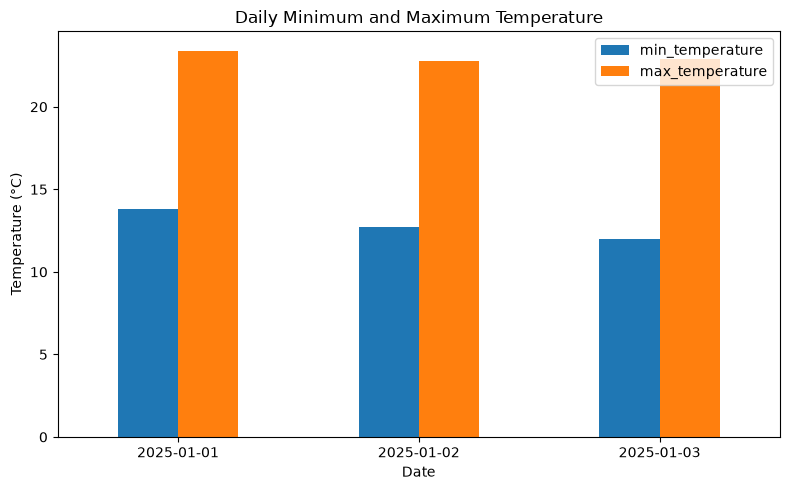

In [24]:
daily_weather[["min_temperature", "max_temperature"]].plot(
    kind="bar",
    figsize=(8, 5),
    title="Daily Minimum and Maximum Temperature"
)

plt.ylabel("Temperature (°C)")
plt.xlabel("Date")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
import sqlite3

conn = sqlite3.connect("weather.db")

df.to_sql(
    "hourly_weather",
    conn,
    if_exists="replace",
    index=False
)

72

In [26]:
query = """
SELECT
    DATE(time) AS date,
    ROUND(AVG(temperature_2m), 2) AS avg_temperature,
    MIN(temperature_2m) AS min_temperature,
    MAX(temperature_2m) AS max_temperature,
    ROUND(AVG(relative_humidity_2m), 2) AS avg_humidity
FROM hourly_weather
GROUP BY DATE(time)
ORDER BY date;
"""

pd.read_sql_query(query, conn)

,date,avg_temperature,min_temperature,max_temperature,avg_humidity
0,2025-01-01,18.38,13.8,23.4,72.58
1,2025-01-02,17.26,12.7,22.8,73.17
2,2025-01-03,17.19,12.0,22.9,73.83


In [27]:
conn.close()